In [1]:
#Dataset Generator
import random

def generate_dataset(filename="arithmetic_dataset.txt", min_val=1, max_val=100):
    data_ls = []
    print("Data Generating....")
    for i in range(min_val, max_val):
        for j in range(min_val, max_val):
            eq = f'{i}+{j}={i+j}e'
            length = 11 - len(eq)
            eq += 'p'*length
            eq+='\n'
            data_ls.append(eq)
            eq = f'{i}-{j}={abs(i-j)}e'
            length = 11 - len(eq)
            eq += 'p'*length
            eq+='\n'
            data_ls.append(eq)
            eq = f'{i}*{j}={i*j}e'
            length = 11 - len(eq)
            eq += 'p'*length
            eq+='\n'
            data_ls.append(eq)
    print("Data Shuffling....")
    random.shuffle(data_ls)
    print("Saving to file....")
    with open(filename,"w") as file:
        file.write("".join(data_ls))
    print(f"Dataset saved to {filename}")

generate_dataset()

Data Generating....
Data Shuffling....
Saving to file....
Dataset saved to arithmetic_dataset.txt


In [2]:
class ArithmeticTokenizer: # character level tokenizer in use.
    def __init__(self):
        self.character = [
            'p','0','1','2','3','4','5','6','7','8','9','+','-','*','=','e'
        ]
        self.char_to_token = {char: idx for idx, char in enumerate(self.character)}
        self.token_to_char = {idx: char for idx, char in enumerate(self.character)}

        self.max_length = 11   # fixed max length 11-nary model

    def encode(self, text):
        tokens = []
        text = "".join(text.split())
        for c in text:
            tokens.append(self.char_to_token[c])
        if len(text)<self.max_length:
            return self.pad_to_max(tokens)
        return tokens
    
    def decode(self, tokens):
        equation = []
        for token in tokens:
            character = self.token_to_char[int(token)]
            if character in ['p', 'e']:
                continue
            equation.append(character)
        return ''.join(equation)

    def pad_to_max(self, token_ids): #incase of cmd inputs and you are lazy
        token_ids.append(self.char_to_token['e'])
        for _ in range(self.max_length - len(token_ids)):
            token_ids.append(self.char_to_token['p'])
        return token_ids
demo = ArithmeticTokenizer()
print(demo.encode("45*33=123eppp"))

[5, 6, 13, 4, 4, 14, 2, 3, 4, 15, 0, 0, 0]


In [4]:
import torch
import torch.nn as nn

class ArithmeticEmbedding(nn.Module):
    def __init__(self, vocab_size=16, embedding_dim=64):
        super().__init__()

        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim
        )

    def forward(self, x):
        return self.token_embedding(x)

demo_embed = ArithmeticEmbedding(vocab_size=len(demo.character), embedding_dim=8)
sample = demo.encode("92+47=139ep")

x = torch.tensor(sample, dtype=torch.long)
output = demo_embed(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print(x)
print(output)

Input shape: torch.Size([11])
Output shape: torch.Size([11, 8])
tensor([10,  3, 11,  5,  8, 14,  2,  4, 10, 15,  0])
tensor([[-0.8013,  0.6287, -0.4176, -1.3499, -0.7453, -0.3518, -0.0946,  0.0882],
        [ 2.4188,  0.6014, -1.0414, -2.5204, -0.4047, -0.5530, -2.1456, -0.2567],
        [-0.0526, -0.7691, -0.3521,  0.9698,  1.3125, -1.7796,  0.0551,  0.0587],
        [-2.9040, -0.5220,  0.5711, -0.5171, -3.1595,  1.5724,  0.2965, -0.7404],
        [-0.2084, -1.1203, -0.7300, -1.0807,  0.0523, -2.1541,  0.5464, -0.2143],
        [ 1.0053, -0.6901,  0.4669, -0.4637,  1.4084, -0.3091, -2.5139, -0.2896],
        [ 0.0543,  0.1014, -0.3005,  0.1824,  0.3213, -0.8102,  0.5198, -0.7987],
        [ 0.2485, -0.3539,  0.0863,  0.6590,  0.0451,  1.7748, -2.0522,  0.9704],
        [-0.8013,  0.6287, -0.4176, -1.3499, -0.7453, -0.3518, -0.0946,  0.0882],
        [ 0.0872, -0.9746,  0.3996, -0.4080, -0.7610,  1.2167, -0.0380, -0.5711],
        [-1.0510,  0.2547,  0.1312,  0.8284, -1.2645,  0.9803, 

In [ ]:
class PositionalEmbedding(nn.Module):
    def __init__(self, max_length=11, embedding_dim=64):
        super().__init__()

        self.position_embedding = nn.Embedding(
            num_embeddings=max_length,
            embedding_dim=embedding_dim
        )

    def forward(self, x):
        seq_length = x.size(1)
        positions = torch.arange(seq_length)
        return self.position_embedding(positions)

In [68]:
class ArithmeticEmbedding(nn.Module):
    def __init__(self, vocab_size=16,max_length =11, embedding_dim=64):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, x):
        positions = torch.arange(x.size(1))
        token_emb = self.token_embedding(x)
        position_emb = self.position_embedding(positions)

        return token_emb + position_emb, token_emb, position_emb

demo_embed = ArithmeticEmbedding(vocab_size=len(demo.character), embedding_dim=64)
sample = demo.encode("92+47=139ep")

x = torch.tensor([sample], dtype=torch.long)
output, embed, pos_embed = demo_embed(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Token Embedding shape:", embed.shape)
print("Positional shape:", pos_embed.shape)
# print(x)
# print(output)

Input shape: torch.Size([1, 11])
Output shape: torch.Size([1, 11, 64])
Token Embedding shape: torch.Size([1, 11, 64])
Positional shape: torch.Size([11, 64])


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

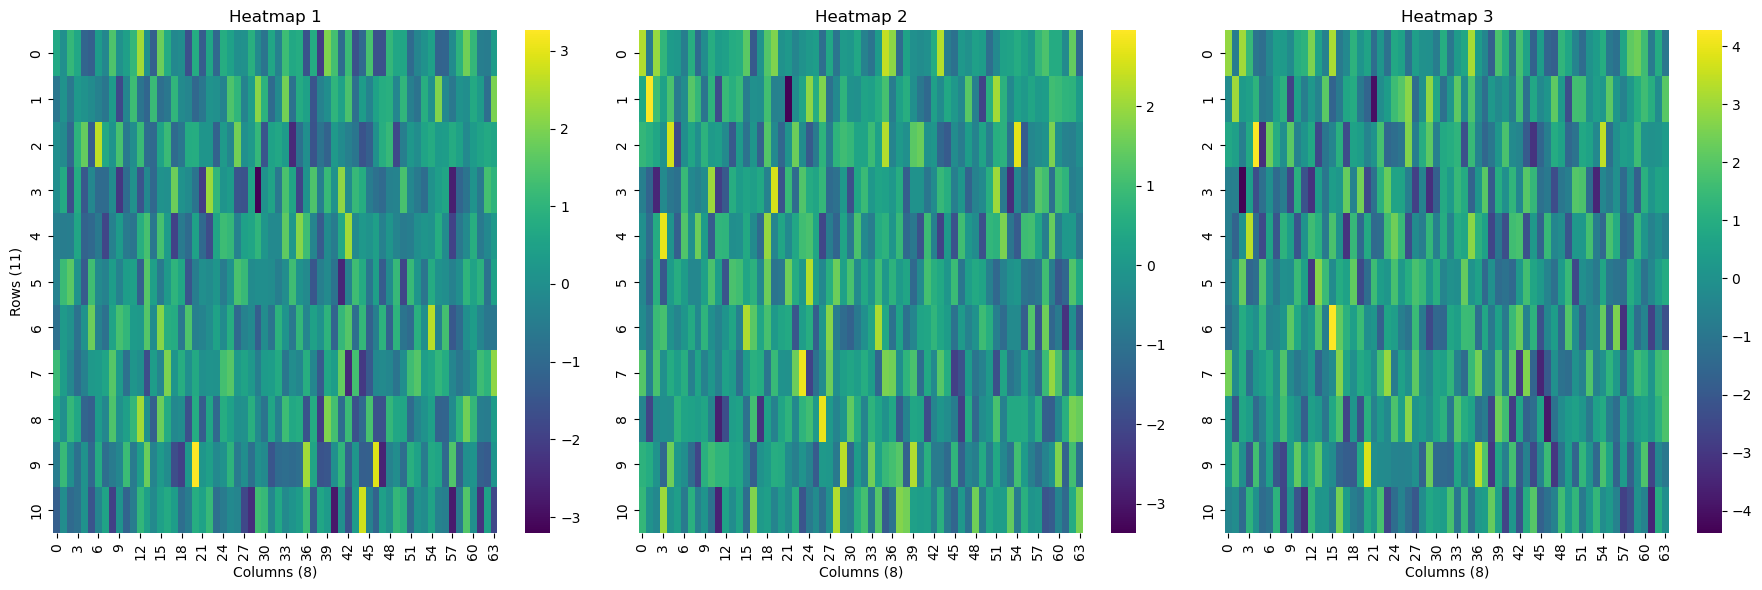

In [70]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

grid1 = embed[0].detach().cpu().numpy()
grid2 = pos_embed.detach().cpu().numpy()
grid3 = output[0].detach().cpu().numpy()

sns.heatmap(grid1, ax=axes[0], cmap="viridis")
# sns.heatmap(grid1, ax=axes[0], annot=True, fmt=".2f", cmap="viridis")
axes[0].set_title("Heatmap 1")
axes[0].set_ylabel("Rows (11)")
axes[0].set_xlabel("Columns (8)")

sns.heatmap(grid2, ax=axes[1], cmap="viridis")
# sns.heatmap(grid2, ax=axes[1], annot=True, fmt=".2f", cmap="plasma")
axes[1].set_title("Heatmap 2")
axes[1].set_xlabel("Columns (8)")

sns.heatmap(grid3, ax=axes[2], cmap="viridis")
# sns.heatmap(grid3, ax=axes[2], annot=True, fmt=".2f", cmap="magma")
axes[2].set_title("Heatmap 3")
axes[2].set_xlabel("Columns (8)")

plt.tight_layout()
plt.show()

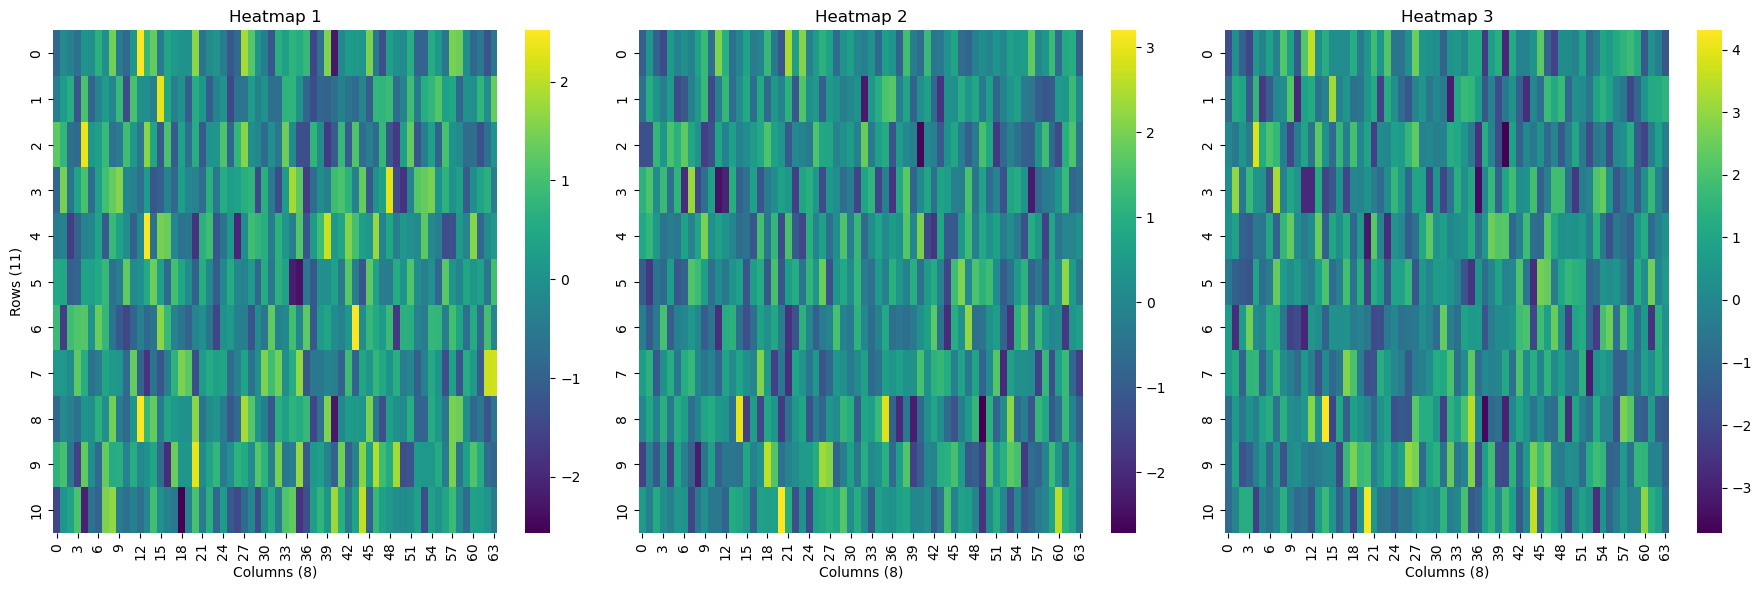

In [67]:
sample = demo.encode("92+47=139ep")

x = torch.tensor([sample], dtype=torch.long)
output, embed, pos_embed = model.embedding(x)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

grid1 = embed[0].detach().cpu().numpy()
grid2 = pos_embed.detach().cpu().numpy()
grid3 = output[0].detach().cpu().numpy()

sns.heatmap(grid1, ax=axes[0], cmap="viridis")
# sns.heatmap(grid1, ax=axes[0], annot=True, fmt=".2f", cmap="viridis")
axes[0].set_title("Heatmap 1")
axes[0].set_ylabel("Rows (11)")
axes[0].set_xlabel("Columns (8)")

sns.heatmap(grid2, ax=axes[1], cmap="viridis")
# sns.heatmap(grid2, ax=axes[1], annot=True, fmt=".2f", cmap="plasma")
axes[1].set_title("Heatmap 2")
axes[1].set_xlabel("Columns (8)")

sns.heatmap(grid3, ax=axes[2], cmap="viridis")
# sns.heatmap(grid3, ax=axes[2], annot=True, fmt=".2f", cmap="magma")
axes[2].set_title("Heatmap 3")
axes[2].set_xlabel("Columns (8)")

plt.tight_layout()
plt.show()

In [48]:
import torch.nn.functional as F

class TransformerDecoderBlock(nn.Module):
    def __init__(self, embedding_dim=64, num_heads=4):
        super().__init__()
        self.attention = nn.MultiheadAttention(embed_dim=embedding_dim, num_heads=num_heads, dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.norm2 = nn.LayerNorm(embedding_dim)
        self.feed_forward = nn.Sequential(
            nn.Linear(embedding_dim, embedding_dim * 4),
            nn.GELU(),
            nn.Linear(embedding_dim * 4, embedding_dim),
        )
    def forward(self, x):
        seq_length = x.size(1)
        causal_mask = torch.triu( torch.ones(seq_length, seq_length, device=x.device), diagonal=1).bool() # Causal Mask
        attention_output, _ = self.attention(x, x, x, attn_mask=causal_mask) # Masked self attention
        x = self.norm1(x + attention_output)
        ff_output = self.feed_forward(x)
        return self.norm2(x + ff_output)

class ArithmeticOutputHead(nn.Module):
    def __init__(self, embedding_dim=64, vocab_size=16):
        super().__init__()
        self.linear1 = nn.Linear(embedding_dim, embedding_dim)
        self.activation = nn.ReLU()
        self.linear2 = nn.Linear(embedding_dim, vocab_size)
    def forward(self, x):
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        return x

In [51]:
class DecoderBlock(nn.Module):
    def __init__(self, embedding_dim=64, num_heads=4, num_layers=4):
        super().__init__()
        self.blocks = nn.Sequential(*[TransformerDecoderBlock(embedding_dim, num_heads) for _ in range(num_layers)])
    def forward(self, x):
        x = self.blocks(x)
        return x

In [52]:
class ArithmeticLLM(nn.Module):
    def __init__(self, vocab_size=16, max_length=11, embedding_dim=64, num_heads=4, num_layers=4):
        super().__init__()
        self.embedding = ArithmeticEmbedding(vocab_size=vocab_size, max_length=max_length, embedding_dim=embedding_dim)
        self.transformer = DecoderBlock(embedding_dim=embedding_dim, num_heads=num_heads, num_layers=num_layers)
        self.output_head = ArithmeticOutputHead(embedding_dim=embedding_dim, vocab_size=vocab_size)

    def forward(self, x):
        x, _, _ = self.embedding(x)
        x = self.transformer(x)
        logits = self.output_head(x)
        return logits

In [43]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split

class ArithmeticDataset(Dataset):
    def __init__(self, file_path, tokenizer):
        self.data = []

        with open(file_path, "r") as f:
            for line in f:
                text = "".join(line.split())

                if not text:
                    continue

                if 'e' not in text:
                    text += 'e'

                if len(text) > tokenizer.max_length:
                    raise ValueError(f"Sequence too long: {text}")

                text = text.ljust(tokenizer.max_length, 'p')

                tokens = [
                    tokenizer.char_to_token[c]
                    for c in text
                ]

                self.data.append(torch.tensor(tokens, dtype=torch.long))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sequence = self.data[idx]

        x = sequence[:-1]
        y = sequence[1:]

        return x, y

In [53]:
from torch.utils.data import DataLoader, random_split

tokenizer = ArithmeticTokenizer()
dataset = ArithmeticDataset("arithmetic_dataset.txt", tokenizer)

train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32)


model = ArithmeticLLM(vocab_size=len(tokenizer.character), embedding_dim=64, num_heads=4, num_layers=4)

criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.char_to_token['p'])

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=0.01
)
print("Dataset size:", len(dataset))
# print("Parameters:", sum(p.numel() for p in model.parameters()))

Dataset size: 29403


In [54]:
epochs = 30

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for x, y in train_loader:
        logits = model(x)
        loss = criterion(
            logits.reshape(-1, len(tokenizer.character)),
            y.reshape(-1)
        )

        # Backpropagation
        optimizer.zero_grad(set_to_none=True)

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

    if val_loader is not None:
        model.eval()
        val_loss = 0

        with torch.no_grad():
            for x, y in val_loader:
                logits = model(x)

                loss = criterion(
                    logits.reshape(-1, len(tokenizer.character)),
                    y.reshape(-1)
                )

                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.4f} "
            f"Val Loss: {avg_val_loss:.4f}"
        )

# Save model
torch.save(model.state_dict(), "arithmetic_llm.pth")

Epoch [1/30] Train Loss: 1.7456 Val Loss: 1.6274
Epoch [2/30] Train Loss: 1.5779 Val Loss: 1.5167
Epoch [3/30] Train Loss: 1.4818 Val Loss: 1.4451
Epoch [4/30] Train Loss: 1.4373 Val Loss: 1.4062
Epoch [5/30] Train Loss: 1.4091 Val Loss: 1.3804
Epoch [6/30] Train Loss: 1.3833 Val Loss: 1.3477
Epoch [7/30] Train Loss: 1.3473 Val Loss: 1.3019
Epoch [8/30] Train Loss: 1.3011 Val Loss: 1.2512
Epoch [9/30] Train Loss: 1.2556 Val Loss: 1.2106
Epoch [10/30] Train Loss: 1.2230 Val Loss: 1.1821
Epoch [11/30] Train Loss: 1.1985 Val Loss: 1.1643
Epoch [12/30] Train Loss: 1.1797 Val Loss: 1.1500
Epoch [13/30] Train Loss: 1.1654 Val Loss: 1.1312
Epoch [14/30] Train Loss: 1.1513 Val Loss: 1.1262
Epoch [15/30] Train Loss: 1.1416 Val Loss: 1.1172
Epoch [16/30] Train Loss: 1.1331 Val Loss: 1.1072
Epoch [17/30] Train Loss: 1.1245 Val Loss: 1.0995
Epoch [18/30] Train Loss: 1.1195 Val Loss: 1.0964
Epoch [19/30] Train Loss: 1.1127 Val Loss: 1.0922
Epoch [20/30] Train Loss: 1.1078 Val Loss: 1.0873
Epoch [21

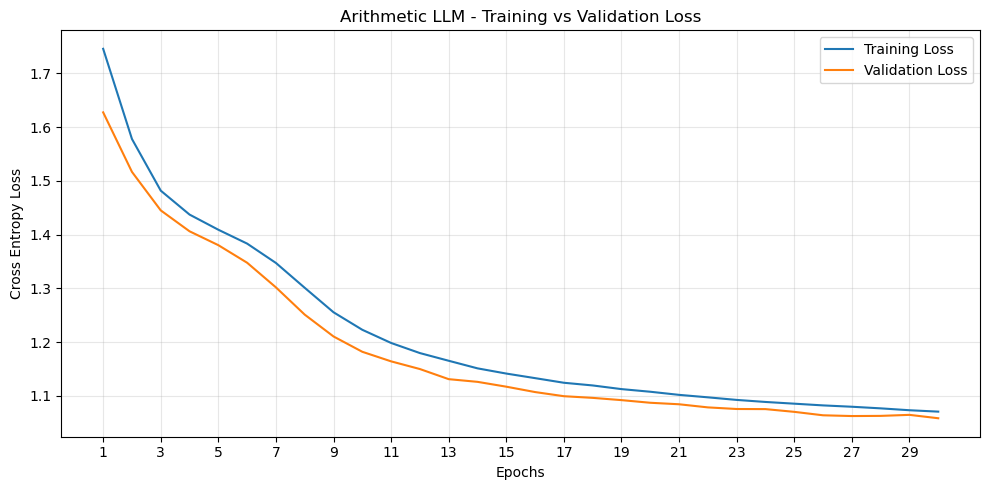

In [71]:
train_losses = [
    1.7456, 1.5779, 1.4818, 1.4373, 1.4091,
    1.3833, 1.3473, 1.3011, 1.2556, 1.2230,
    1.1985, 1.1797, 1.1654, 1.1513, 1.1416,
    1.1331, 1.1245, 1.1195, 1.1127, 1.1078,
    1.1020, 1.0974, 1.0926, 1.0888, 1.0856,
    1.0824, 1.0799, 1.0769, 1.0734, 1.0708
] # forgot to store in list in the above one append loss using a list and then directly execute this code.

val_losses = [
    1.6274, 1.5167, 1.4451, 1.4062, 1.3804,
    1.3477, 1.3019, 1.2512, 1.2106, 1.1821,
    1.1643, 1.1500, 1.1312, 1.1262, 1.1172,
    1.1072, 1.0995, 1.0964, 1.0922, 1.0873,
    1.0845, 1.0787, 1.0757, 1.0755, 1.0704,
    1.0640, 1.0626, 1.0629, 1.0648, 1.0585
]

epochs = range(1, 31)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Cross Entropy Loss")
plt.title("Arithmetic LLM - Training vs Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()

In [72]:
def generate(model, tokenizer, prompt, max_new_tokens=11):
    model.eval()
    prompt = "".join(prompt.split())

    x = torch.tensor(
        [[tokenizer.char_to_token[c] for c in prompt]],
        dtype=torch.long,
    )
    with torch.no_grad():
        for _ in range(max_new_tokens):
            x = x[:, -tokenizer.max_length:]
            logits = model(x)
            next_token_logits = logits[:, -1, :]
            next_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)

            x = torch.cat((x, next_token), dim=1)

            if next_token.item() == tokenizer.char_to_token['e']:
                break
    return tokenizer.decode(x[0].tolist())

In [64]:
result = generate(
    model=model,
    tokenizer=tokenizer,
    prompt="99*99=",
    max_new_tokens=5,
)

print("Generated:", result)

Generated: 99*99=9001
